# AlphaPulldown inputs

In [5]:
import requests

def get_fasta(uniprot_id):
    # 1) Try UniProtKB
    url_kb = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}.fasta"
    r = requests.get(url_kb)

    if r.status_code == 200 and r.text.strip():
        seq = "".join([_ for _ in r.text.splitlines() if not _.startswith('>')])
        return seq

    # 2) Fallback: search UniParc for the accession
    search_url = f"https://rest.uniprot.org/uniparc/search?query={uniprot_id}&format=json"
    r = requests.get(search_url)

    if r.status_code != 200:
        raise Exception("UniParc search failed")

    data = r.json()
    results = data.get("results", [])

    if not results:
        raise Exception("No UniParc entry found")

    # Take first hit (usually correct)
    upi = results[0]["uniParcId"]

    # 3) Fetch FASTA from UniParc
    fasta_url = f"https://rest.uniprot.org/uniparc/{upi}?format=fasta"
    r = requests.get(fasta_url)
    
    if r.status_code == 200:
        seq = "".join([_ for _ in r.text.splitlines() if not _.startswith('>')])
        return seq

    raise Exception("Failed to retrieve FASTA from UniParc")
    

allseqs = {}
targets = []
with open(f"../data/negatome_manual_1k.txt") as ifile:
    for idx,line in enumerate(ifile):
        uidA, uidB = line.split()[:2]
        seqA = get_fasta(uidA)
        seqB = get_fasta(uidB)
            
        allseqs[uidA] = seqA
        allseqs[uidB] = seqB
        targets.append(f"{uidA};{uidB}")
        if idx>10: break
        
with open(f"targets.fasta", 'w') as ofile:
    for uid, seq in allseqs.items():
        print(f">{uid}\n{seq}", file=ofile)
        
with open(f"targets.txt", 'w') as ofile:
    print("\n".join(targets), file=ofile)        


# STRING binders in Pfam families

In [ ]:
import json, os, sys, time
import pandas as pd
from family_hits import family_hits


def _done(path):
    if not os.path.exists(path):
        return set()
    with open(path) as fh:
        return {(d["A"], d["B"]) for d in map(json.loads, fh)}

min_escore=0.4
pause=1.0

Sum, Hit, Err = (os.path.join('..', 'data', f) for f in ("summary.jsonl", "hits.jsonl", "errors.jsonl"))
pairs = pd.read_csv("../data/negatome_results_complete.tsv", sep="\t", header=None, usecols=[2, 5], names=["uid_A", "uid_B"], skiprows=1)
pairs = pairs.apply(lambda c: c.str.split("-").str[0]).drop_duplicates()
done = _done(Sum)
todo = [(a, b) for a, b in pairs.itertuples(index=False) if (a, b) not in done]
print(f"{len(pairs)} pairs, {len(done)} done, {len(todo)} to run")
with open(Sum, "a") as fs, open(Hit, "a") as fh, open(Err, "a") as fe:
    for i, (a, b) in enumerate(todo, 1):
        print(i,a,b)
        t0 = time.time()
        try:
            summ, hits = family_hits(a, b, min_escore=min_escore)
        except Exception as ex:  # log and move on; retried next run
            fe.write(json.dumps({"uid_A": a, "uid_B": b, "error": repr(ex)}) + "\n"); fe.flush()
            continue
        for rec in hits.to_dict("records"):
            fh.write(json.dumps({"pair_A": a, "pair_B": b, **rec}) + "\n")
        fs.write(json.dumps(summ) + "\n")      # summary last = pair is complete
        fh.flush(); fs.flush()
        if i % 10 == 0 or i == len(todo):
            print(f"  {i}/{len(todo)}  {a}-{b}  {summ['status']}  hits={summ.get('n_hits', 0)}", flush=True)
        time.sleep(max(0, pause - (time.time() - t0)))   # be polite to STRING/InterPro
            
            
            

# Process results and prepare figures

## Figure 1: scatter plots

P06493 P24864 contradicts 0.9136409524199148 0.889782 [0.9136409524199148, 0.889782, 1]
B7Z018 Q02870 not-tested 0.8272875192022819 0.507051 [0.8272875192022819, 0.507051, 0]
P25311 P61769 supports-strong 0.8538458266555895 0.880355 [0.8538458266555895, 0.880355, 1]
Q9Y2Q0 Q3MIR4 supports-strong 0.923383902113484 0.867872 [0.923383902113484, 0.867872, 1]
P30154 P63151 supports-strong 0.855701583923711 0.766409 [0.855701583923711, 0.766409, 0]
P11084 P30154 supports-strong 0.8749394049186527 0.803418 [0.8749394049186527, 0.803418, 0]
Q91XD2 Q15404 not-tested 0.8583910661443037 0.863486 [0.8583910661443037, 0.863486, 0]
Q13868 Q9NPD3 supports-weak 0.8539923716512801 0.77515 [0.8539923716512801, 0.77515, 1]
Q06265 Q9NPD3 contradicts 0.850330553068805 0.781927 [0.850330553068805, 0.781927, 1]
P30154 Q15173 supports-strong 0.8146003263432735 0.787507 [0.8146003263432735, 0.787507, 1]
O43172 O43447 contradicts 0.8243277642055221 0.73966 [0.8243277642055221, 0.73966, 1]
O60423 Q3MIR4 supports

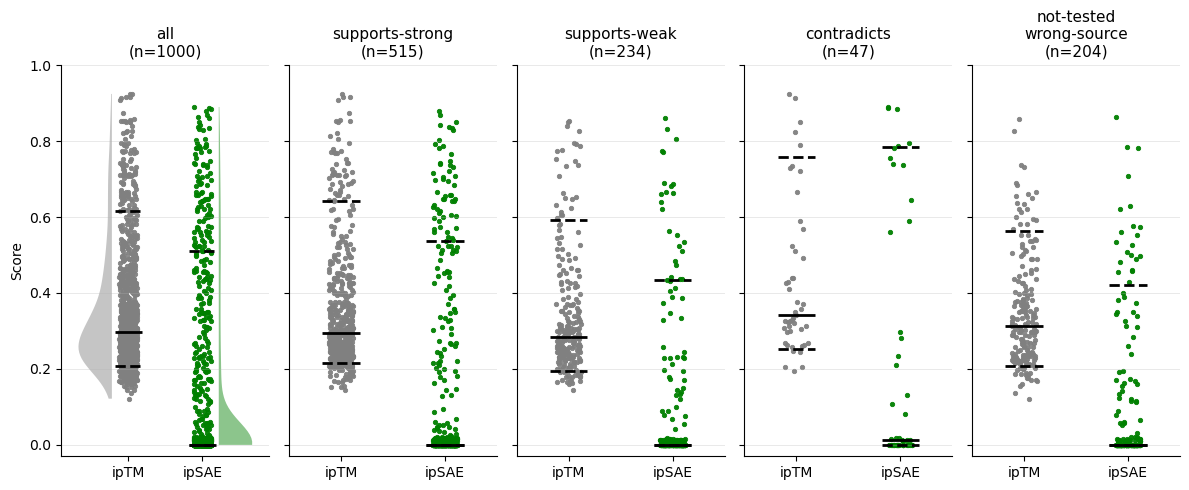

In [6]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kstest
import os
from scipy.stats import mannwhitneyu, kstest

rng = np.random.default_rng(2)

hp = os.path.join('..', 'data', 'families_hits.jsonl')
families_hits = pd.read_json(hp, lines=True)

data={}

idx=0
negatome_results = pd.read_csv(Path("..", "data", "negatome_results_complete.tsv"), sep='\t')
for acc1,acc2,label,iptm,ipsae in zip(negatome_results['uniprot_A'],
                                      negatome_results['uniprot_B'],
                                      negatome_results['label'],
                                      negatome_results['iptm'],
                                      negatome_results['ipsae']):    
    
    homobinder_string_v1 = len(families_hits[(families_hits["pair_A"]==acc1) & (families_hits["pair_B"]==acc2) & (families_hits["escore"]>0.9)])
    homobinder_string_v2 = len(families_hits[(families_hits["pair_A"]==acc2) & (families_hits["pair_B"]==acc1) & (families_hits["escore"]>0.9)])

    _a = data.setdefault(label, [])
    _a.append([float(iptm),float(ipsae), 1 if homobinder_string_v1 or homobinder_string_v2 else 0])
    
    if iptm>0.8:
        print(acc1, acc2, label, iptm, ipsae, _a[-1])
    
labels = ["all", "supports-strong", "supports-weak", "contradicts", "not-tested\nwrong-source"]
metrics = ["ipTM", "ipSAE"]
colors = ["grey", "green"]

data['not-tested\nwrong-source']=[]
for other_label in ['not-tested', 'wrong-source']:
    for v in data[other_label]:
        data['not-tested\nwrong-source'].append(v)
    
    
data['all']=[]
for other_label in labels[1:]:
    for v in data[other_label]:
        data['all'].append(v)    
    

if 1:
    print("K-S test for all pairs of evidence classes")
    for il1 in range(1,len(labels)):
        for il2 in range(il1+1,len(labels)):
            print(f"\t{labels[il1]:>10s} {labels[il2]:>10s}")    

            for score_i, score_name in enumerate(['iptm', 'ipsae']):
                x = np.asarray(data[labels[il1]])[:,score_i]
                y = np.asarray(data[labels[il2]])[:,score_i]

                _=kstest(x, y)
                print(f"\t\t{score_name} pv={_.pvalue:.2e}")    


jitter = 0.12        # half-width of horizontal point spread
violin_gap = 0.22    # distance from point column to violin base


def half_violin(ax, y, pos, side, color):
    """Draw only the left or right half of a violin at x=pos."""
    parts = ax.violinplot(y, positions=[pos], widths=0.9,
                          showextrema=False, showmedians=False)
    for body in parts["bodies"]:
        verts = body.get_paths()[0].vertices
        if side == "left":
            verts[:, 0] = np.minimum(verts[:, 0], pos)
        else:
            verts[:, 0] = np.maximum(verts[:, 0], pos)
        body.set_facecolor(color)
        body.set_edgecolor("none")
        body.set_alpha(0.45)

        
        
    

fig, axes = plt.subplots(1, len(labels), figsize=(12, 5), sharey=True)
for ax, label in zip(axes, labels):
    values = np.asarray(data[label])
    for j, (metric, color) in enumerate(zip(metrics, colors)):
        y = values[:, j]
        new_colors = []
        for _v in values[:,2]:
            if _v:
                new_colors.append('red')
            else:
                new_colors.append(color)

        x = j + rng.uniform(-jitter, jitter, len(y))
        ax.scatter(x, y, s=10, facecolors=color, alpha=0.95,
                   edgecolor=color, linewidth=0.6)
        ax.hlines(np.median(y), j - 0.18, j + 0.18, color="black", lw=2.0)

        
        ax.hlines(np.percentile(y,10), j - 0.18, j + 0.18, color="k", lw=2.0, ls='--')    
        ax.hlines(np.percentile(y,90), j - 0.18, j + 0.18, color="k", lw=2.0, ls='--')

        if label == "all":
            side = "left" if j == 0 else "right"
            pos = j - violin_gap if j == 0 else j + violin_gap
            half_violin(ax, y, pos, side, color)

    ax.set_title(f"{label}\n(n={len(values)})", fontsize=11)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(metrics)
    ax.set_xlim(-0.9 if label == "all" else -0.5,
                1.9 if label == "all" else 1.5)
    ax.tick_params(labelsize=10)
    ax.grid(axis="y", lw=0.5, alpha=0.4)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)

axes[0].set_ylabel("Score")
axes[0].set_ylim(-0.03, 1.0)

fig.tight_layout()
fig.savefig("../figures/Figure1_scatters_plots.png", dpi=300)

## Figure 2: logictic regression

slope (ipTM) 3.66 +- 0.62
slope (ipSAE) 2.76 +- 0.41


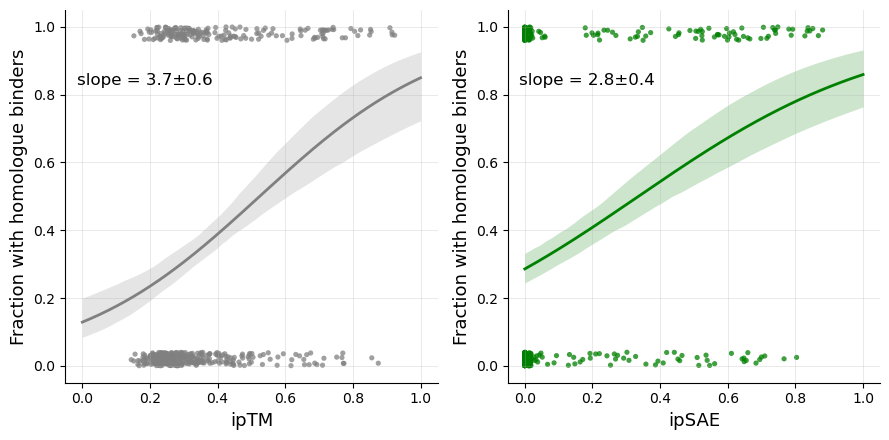

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(2)


# ------------------------------------------------------------ logistic helpers
def fit_logistic(x, y, l2=1e-2):
    """Return (b0, b1). A small L2 penalty keeps the fit finite when the
    classes are perfectly separated (common in small groups)."""
    def nll(b):
        z = b[0] + b[1] * x
        return np.sum(np.logaddexp(0, z) - y * z) + l2 * b[1] ** 2
    return minimize(nll, x0=[0.0, 0.0], method="BFGS").x


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def bootstrap_band(x, y, grid, n_boot=300):
    curves = []
    slopes = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        if y[idx].min() == y[idx].max():      # resample has only 0s or 1s
            continue
        b = fit_logistic(x[idx], y[idx])
        slopes.append(b[1])
        curves.append(sigmoid(b[0] + b[1] * grid))
        
    return np.percentile(curves, [2.5, 97.5], axis=0), slopes


def binned_fraction(x, y, edges):
    """Fraction of 1s per bin with Wilson 95% interval."""
    centres, frac, lo, hi = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = (x >= a) & (x < b) if b < edges[-1] else (x >= a) & (x <= b)
        n = m.sum()
        if n == 0:
            continue
        k = y[m].sum()
        p = k / n
        z = 1.96
        den = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / den
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
        centres.append(x[m].mean()); frac.append(p)
        lo.append(p - (c - h)); hi.append((c + h) - p)
    return np.array(centres), np.array(frac), np.array([lo, hi])


# ------------------------------------------------------------------- plotting
grid = np.linspace(0, 1, 200)
edges = np.linspace(0, 1, 6)            # 5 bins for the binned fractions

labels = ["supports-strong"]
metrics = ["ipTM", "ipSAE"]
colors = ["grey", "green"]

fig, axes = plt.subplots(len(labels), 2, figsize=(9, 4.5), sharex=True, sharey=0)

for col, label in enumerate(labels):
    arr = np.asarray(data[label], dtype=float)
    y = arr[:, 2]
    for row, (metric, color) in enumerate(zip(metrics, colors)):
        try:
            ax = axes[row, col]
        except:
            ax = axes[row]
            
        x = arr[:, row]

        # raw outcomes at 0/1
        yj = y + np.where(y == 1, -1, 1) * rng.uniform(0, 0.04, len(y))
        ax.scatter(x, yj, s=14, color=color, alpha=0.75, edgecolor="none")

        # logistic fit + bootstrap 95% CI
        b = fit_logistic(x, y)
        (lo, hi), slopes = bootstrap_band(x, y, grid)
        ax.fill_between(grid, lo, hi, color=color, alpha=0.2, lw=0)
        ax.plot(grid, sigmoid(b[0] + b[1] * grid), color=color, lw=2)

        
        print(f"slope ({metric}) {np.mean(slopes):.2f} +- {np.std(slopes):.2f}")


        ax.text(0.03, 0.83, f"slope = {np.mean(slopes):.1f}±{np.std(slopes):.1f}", transform=ax.transAxes,
                fontsize=12, va="top")
        ax.grid(lw=0.5, alpha=0.4)
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)

        ax.set_ylabel(f"Fraction with homologue binders", fontsize=13)
        ax.set_xlabel(metric, fontsize=13)


fig.tight_layout()
fig.savefig("../figures/Figure2_logistic_regression.png", dpi=300)